In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Iris dataset
df = pd.read_csv("iris.csv")

# Display first five records
print("First five records:")
display(df.head())

First five records:


,Sepal_length,Sepal_width,Petal_length,Petal_width,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [2]:
# Dataset dimensions
print("Dataset dimensions:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Summary information
print("\nDataset information:")
df.info()

Dataset dimensions: (150, 5)

Column names:
['Sepal_length', 'Sepal_width', 'Petal_length', 'Petal_width', 'Species']

Data types:
Sepal_length    float64
Sepal_width     float64
Petal_length    float64
Petal_width     float64
Species             str
dtype: object

Missing values:
Sepal_length    0
Sepal_width     0
Petal_length    0
Petal_width     0
Species         0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal_length  150 non-null    float64
 1   Sepal_width   150 non-null    float64
 2   Petal_length  150 non-null    float64
 3   Petal_width   150 non-null    float64
 4   Species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [3]:
# Numerical columns
numeric_columns = [
    "Sepal_length",
    "Sepal_width",
    "Petal_length",
    "Petal_width"
]

# Calculate statistics using NumPy
for column in numeric_columns:
    values = df[column].dropna().to_numpy()

    print("\n", column)
    print("Mean:", np.mean(values))
    print("Median:", np.median(values))
    print("Standard Deviation:", np.std(values))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))


 Sepal_length
Mean: 5.843333333333334
Median: 5.8
Standard Deviation: 0.8253012917851409
Minimum: 4.3
Maximum: 7.9

 Sepal_width
Mean: 3.0540000000000003
Median: 3.0
Standard Deviation: 0.4321465800705435
Minimum: 2.0
Maximum: 4.4

 Petal_length
Mean: 3.758666666666666
Median: 4.35
Standard Deviation: 1.7585291834055212
Minimum: 1.0
Maximum: 6.9

 Petal_width
Mean: 1.1986666666666668
Median: 1.3
Standard Deviation: 0.7606126185881716
Minimum: 0.1
Maximum: 2.5


In [4]:
correlation = np.corrcoef(
    df["Sepal_length"],
    df["Petal_length"]
)[0, 1]

print("Correlation:", round(correlation, 3))

Correlation: 0.872


In [5]:
species_means = df.groupby("Species")[numeric_columns].mean()

print("Mean measurements for each species:")
display(species_means)

Mean measurements for each species:


,Sepal_length,Sepal_width,Petal_length,Petal_width
Species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


In [6]:
highest_species = species_means["Petal_length"].idxmax()
highest_value = species_means["Petal_length"].max()

print("Species with highest average petal length:", highest_species)
print("Average petal length:", round(highest_value, 3))

Species with highest average petal length: Iris-virginica
Average petal length: 5.552


In [7]:
print("Descriptive statistics by species:")
display(df.groupby("Species")[numeric_columns].describe())

Descriptive statistics by species:


Sepal_length                                              \
                       count   mean       std  min    25%  50%  75%  max   
Species                                                                    
Iris-setosa             50.0  5.006  0.352490  4.3  4.800  5.0  5.2  5.8   
Iris-versicolor         50.0  5.936  0.516171  4.9  5.600  5.9  6.3  7.0   
Iris-virginica          50.0  6.588  0.635880  4.9  6.225  6.5  6.9  7.9   

                Sepal_width         ... Petal_length      Petal_width         \
                      count   mean  ...          75%  max       count   mean   
Species                             ...                                        
Iris-setosa            50.0  3.418  ...        1.575  1.9        50.0  0.244   
Iris-versicolor        50.0  2.770  ...        4.600  5.1        50.0  1.326   
Iris-virginica         50.0  2.974  ...        5.875  6.9        50.0  2.026   

                                                    
                      std  min  25%  50%  75%  max  
Species                                             
Iris-setosa      0.107210  0.1  0.2  0.2  0.3  0.6  
Iris-versicolor  0.197753  1.0  1.2  1.3  1.5  1.8  
Iris-virginica   0.274650  1.4  1.8  2.0  2.3  2.5  

[3 rows x 32 columns]

In [8]:
print("Number of samples per species:")
print(df["Species"].value_counts())

Number of samples per species:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


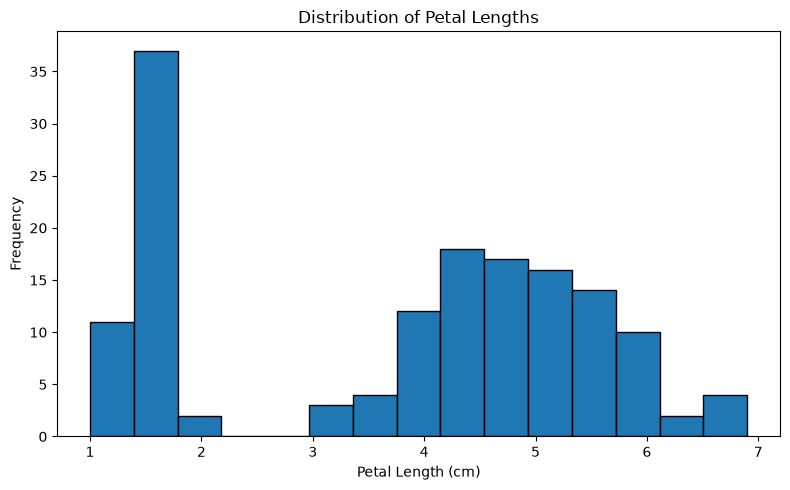

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["Petal_length"], bins=15, edgecolor="black")

plt.title("Distribution of Petal Lengths")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

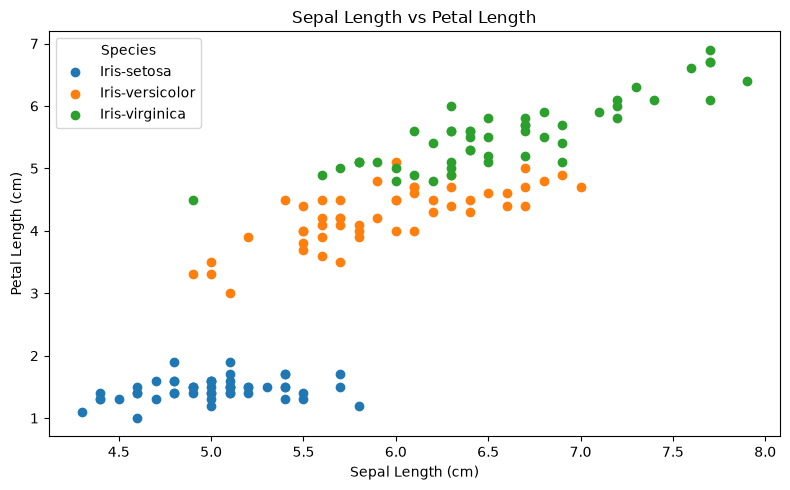

In [10]:
plt.figure(figsize=(8, 5))

for species in df["Species"].unique():
    subset = df[df["Species"] == species]

    plt.scatter(
        subset["Sepal_length"],
        subset["Petal_length"],
        label=species
    )

plt.title("Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend(title="Species")

plt.tight_layout()
plt.show()

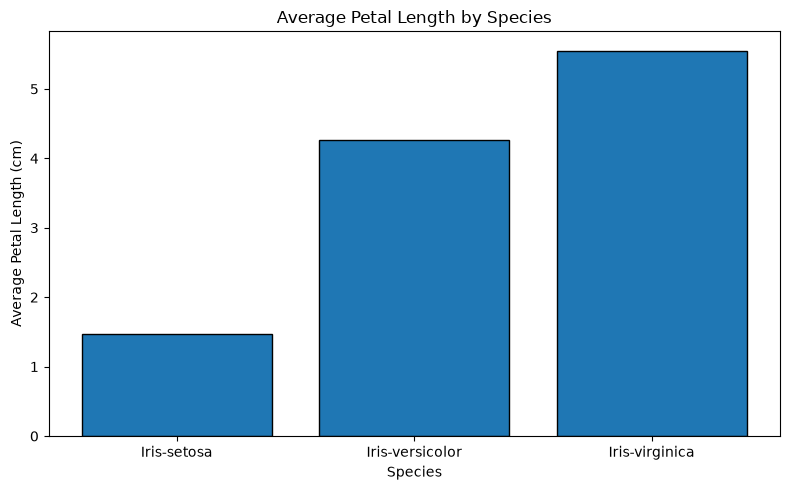

In [11]:
average_petal_length = df.groupby("Species")["Petal_length"].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    average_petal_length.index,
    average_petal_length.values,
    edgecolor="black"
)

plt.title("Average Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Average Petal Length (cm)")

plt.tight_layout()
plt.show()

In [12]:
print("INTERPRETATION OF RESULTS")

print("\n1. Dataset contains", df.shape[0], "flowers.")
print("2. Number of attributes:", df.shape[1])

print("\n3. Missing values:")
print(df.isnull().sum().sum())

print("\n4. Samples belonging to each species:")
print(df["Species"].value_counts())

print("\n5. Average measurements for each species:")
display(species_means.round(3))

print("\n6. Correlation between sepal length and petal length:",
      round(correlation, 3))

print("\n7. Species with the highest average petal length:",
      highest_species)

print("\nConclusion:")
print("Petal length and petal width are useful for distinguishing")
print("the three Iris species. Setosa has much smaller petals,")
print("while Virginica has the highest average petal length.")

INTERPRETATION OF RESULTS

1. Dataset contains 150 flowers.
2. Number of attributes: 5

3. Missing values:
0

4. Samples belonging to each species:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

5. Average measurements for each species:


,Sepal_length,Sepal_width,Petal_length,Petal_width
Species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026



6. Correlation between sepal length and petal length: 0.872

7. Species with the highest average petal length: Iris-virginica

Conclusion:
Petal length and petal width are useful for distinguishing
the three Iris species. Setosa has much smaller petals,
while Virginica has the highest average petal length.
